# Notebook 02 – Thống kê mô tả (bảng T1, T3, T4, T5 và hình)
Notebook này **không viết lại logic làm sạch**. Nó gọi `clean` và `lay_ban` từ `src/sparkmind/cleaning.py`, rồi gọi các hàm tính toán trong `src/sparkmind/stats_desc.py` và hàm vẽ trong `src/sparkmind/ve_hinh.py`.

**Quy tắc:** làm riêng trên 3 bản dữ liệu (chính 361, chặt 297, rất chặt 231). Số của các bản **không bao giờ trộn** trong cùng một bảng.
**Lưu ý khoa học:** điểm sáng tạo ở đây là năng lực sáng tạo **tự nhận thức** (C1–C5 tự chấm), không phải năng lực đo bằng bài kiểm tra.
**Cách dùng:** bấm *Run All*. Chọn nguồn dữ liệu ở ô 1 (`NGUON`).

## 1. Nạp dữ liệu và làm sạch
- `'excel'`: đọc `data/raw/data_raw.xlsx` (không cần MongoDB).
- `'mongo'`: đọc collection `survey_form1` từ MongoDB Atlas (cần file `.env`).

In [1]:
import sys; sys.path.append('../src')
import pandas as pd
from IPython.display import display
from sparkmind import config
from sparkmind.cleaning import clean, lay_ban
from sparkmind.loaders import doc_excel, doc_goc_mongo
from sparkmind.db import lay_db
from sparkmind.stats_desc import bang_mo_ta_mau, bang_alpha, bang_so_sanh, bang_tuong_quan, ma_tran_rho
from sparkmind.ve_hinh import ve_histogram, ve_heatmap

NGUON = 'excel'   # đổi thành 'mongo' khi dữ liệu đã nằm trong MongoDB
raw = doc_excel() if NGUON == 'excel' else doc_goc_mongo(lay_db())
sach = clean(raw)   # gắn cờ chất lượng, không xóa form nào
print('Số form gốc:', len(raw))

# Thư mục lưu kết quả (tạo nếu chưa có)
BANG = config.ROOT / 'outputs' / 'tables'; HINH = config.ROOT / 'outputs' / 'figures'
BANG.mkdir(parents=True, exist_ok=True); HINH.mkdir(parents=True, exist_ok=True)

def luu(bang, ten):
    """Lưu bảng CSV (UTF-8 có BOM để Excel đọc được tiếng Việt) rồi hiện ra."""
    bang.to_csv(BANG / ten, index=False, encoding='utf-8-sig'); display(bang)

Số form gốc: 460


## Cách đọc các bảng (chung cho cả 3 bản)
- **Cronbach's alpha** đo các câu trong cùng một thang có "đi cùng nhau" không. Khoảng 0.7 trở lên thường coi là chấp nhận được; dưới 0.6 là yếu.
- **p** nhỏ (thường < 0.05) nghĩa là sự khác biệt/tương quan khó xảy ra do ngẫu nhiên. Bảng có nhiều phép thử nên đừng quá tin vào một p sát 0.05.
- **Cỡ hiệu ứng** cho biết khác biệt *lớn hay nhỏ*, còn p chỉ cho biết *có khác hay không*.

# 2. Bản chính (kỳ vọng 361 dòng)

In [2]:
ban = lay_ban(sach, 'chinh')   # lấy đúng các dòng thuộc bản chính
assert len(ban) == 361, len(ban)
print('Bản chính:', len(ban), 'dòng')

Bản chính: 361 dòng


### T1 – Mô tả mẫu (bản chính)
Bảng cho biết **mẫu gồm những ai**: bao nhiêu người ở mỗi cấp học, giới tính, dùng công cụ AI nào, dùng thường xuyên cỡ nào, mỗi lần bao lâu, và thu ở đợt nào. Cột `ty_le_%` là phần trăm trên tổng của bản này. Công cụ AI (B1) cho chọn nhiều nên tổng phần trăm có thể vượt 100.

In [3]:
luu(bang_mo_ta_mau(ban), 'T1_sample_main.csv')   # T1

,bien,nhom,so_nguoi,ty_le_%
0,Cấp học,THPT,161,44.6
1,Cấp học,Đại học,124,34.3
2,Cấp học,THCS,76,21.1
3,Giới tính,Nữ,212,58.7
4,Giới tính,Nam,141,39.1
5,Giới tính,Khác,8,2.2
6,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",ChatGPT,279,77.3
7,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Gemini,232,64.3
8,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Copilot,54,15.0
9,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Claude,63,17.5


### T3 – Độ tin cậy Cronbach's alpha (bản chính)
Bảng cho biết **các câu hỏi trong cùng một thang có nhất quán không**: thang sáng tạo tự đánh giá (C1–C5, 5 câu) và thang hành vi dùng AI (B4, 7 câu, đã đảo chiều B4_3 và B4_6 như đã chốt). `co_mau` là số người trả lời đủ mọi câu của thang. Alpha của thang hành vi thường thấp hơn vì 7 câu đo nhiều khía cạnh khác nhau.

In [4]:
luu(bang_alpha(ban), 'T3_alpha_main.csv')   # T3

,thang_do,so_cau,co_mau,alpha
0,Sáng tạo tự đánh giá (C1–C5),5,361,0.814
1,"Hành vi dùng AI (B4_1..B4_7, đảo B4_3, B4_6)",7,361,0.564


### T4 – So sánh điểm sáng tạo giữa các nhóm (bản chính)
Bảng cho biết **điểm sáng tạo (0–100) có khác nhau giữa các nhóm không**: theo cấp học, giới tính (A2) và tần suất dùng AI (B2). Hai nhóm dùng Mann-Whitney; từ ba nhóm dùng Kruskal-Wallis (không cần điểm phân phối chuẩn). `hieu_ung` là cỡ hiệu ứng: epsilon bình phương gần 0 là khác biệt rất nhỏ (khoảng 0.01 nhỏ, 0.06 vừa, 0.14 lớn). Nhóm dưới 5 người bị bỏ và ghi ở cột `nhom_bi_bo`. Đây là so sánh mô tả, chưa hiệu chỉnh cho nhiều phép thử.

In [5]:
luu(bang_so_sanh(ban), 'T4_group_compare_main.csv')   # T4

,bien_nhom,so_nhom,n,phep_thu,thong_ke,p,ten_hieu_ung,hieu_ung,mo_ta_nhom,nhom_bi_bo
0,cap_hoc,3,361,Kruskal-Wallis H,26.564,0.000002,epsilon bình phương,0.069,"THCS: n=76, trung vị=52.5; THPT: n=161, trung ...",
1,A2,3,361,Kruskal-Wallis H,5.705,0.057693,epsilon bình phương,0.010,"Khác: n=8, trung vị=57.5; Nam: n=141, trung vị...",
2,B2,4,361,Kruskal-Wallis H,12.851,0.004969,epsilon bình phương,0.028,"Hầu như mỗi ngày: n=178, trung vị=70.0; Rất hi...",


### T5 – Tương quan Spearman (bản chính)
Bảng cho biết **hai biến có đi cùng chiều không** (`rho` từ -1 đến 1; gần 0 là gần như không liên quan). Gồm 7 câu B4 (chưa đảo chiều, để xem từng câu), tần suất B2, thời gian B5, điểm hành vi và điểm sáng tạo. `n` là số người có đủ cả hai biến. Tương quan không có nghĩa là nguyên nhân.

In [6]:
t5 = bang_tuong_quan(ban); luu(t5, 'T5_spearman_main.csv')   # T5

,bien_1,bien_2,rho,p,n
0,B4_1,B4_2,0.582,0.000000,361
1,B4_1,B4_3,-0.008,0.879673,361
2,B4_1,B4_4,0.472,0.000000,361
3,B4_1,B4_5,0.409,0.000000,361
4,B4_1,B4_6,0.192,0.000238,361
5,B4_1,B4_7,0.461,0.000000,361
6,B4_1,B2_so,0.089,0.093114,361
7,B4_1,B5_so,0.123,0.019342,361
8,B4_1,diem_hanh_vi,0.704,0.000000,361
9,B4_1,diem_sang_tao,0.532,0.000000,361


### Hình – bản chính
Hình 1 là **phân bố điểm sáng tạo** (đường đỏ đứt là ngưỡng 60 và 80 chia mức Thấp / Trung bình / Cao). Hình 2 là **heatmap tương quan** vẽ từ bảng T5 (đỏ là cùng chiều, xanh là ngược chiều).

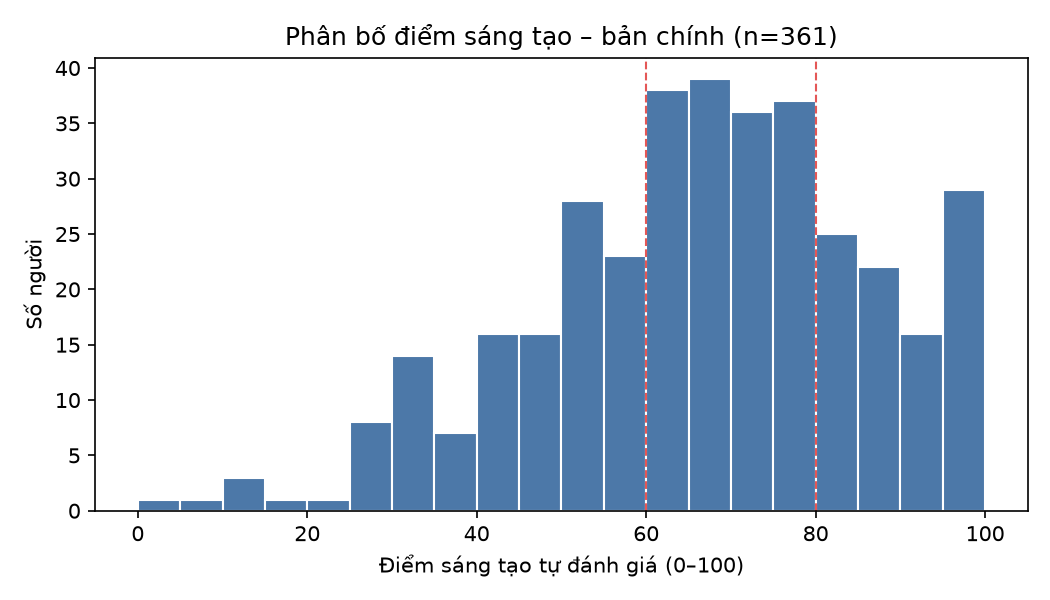

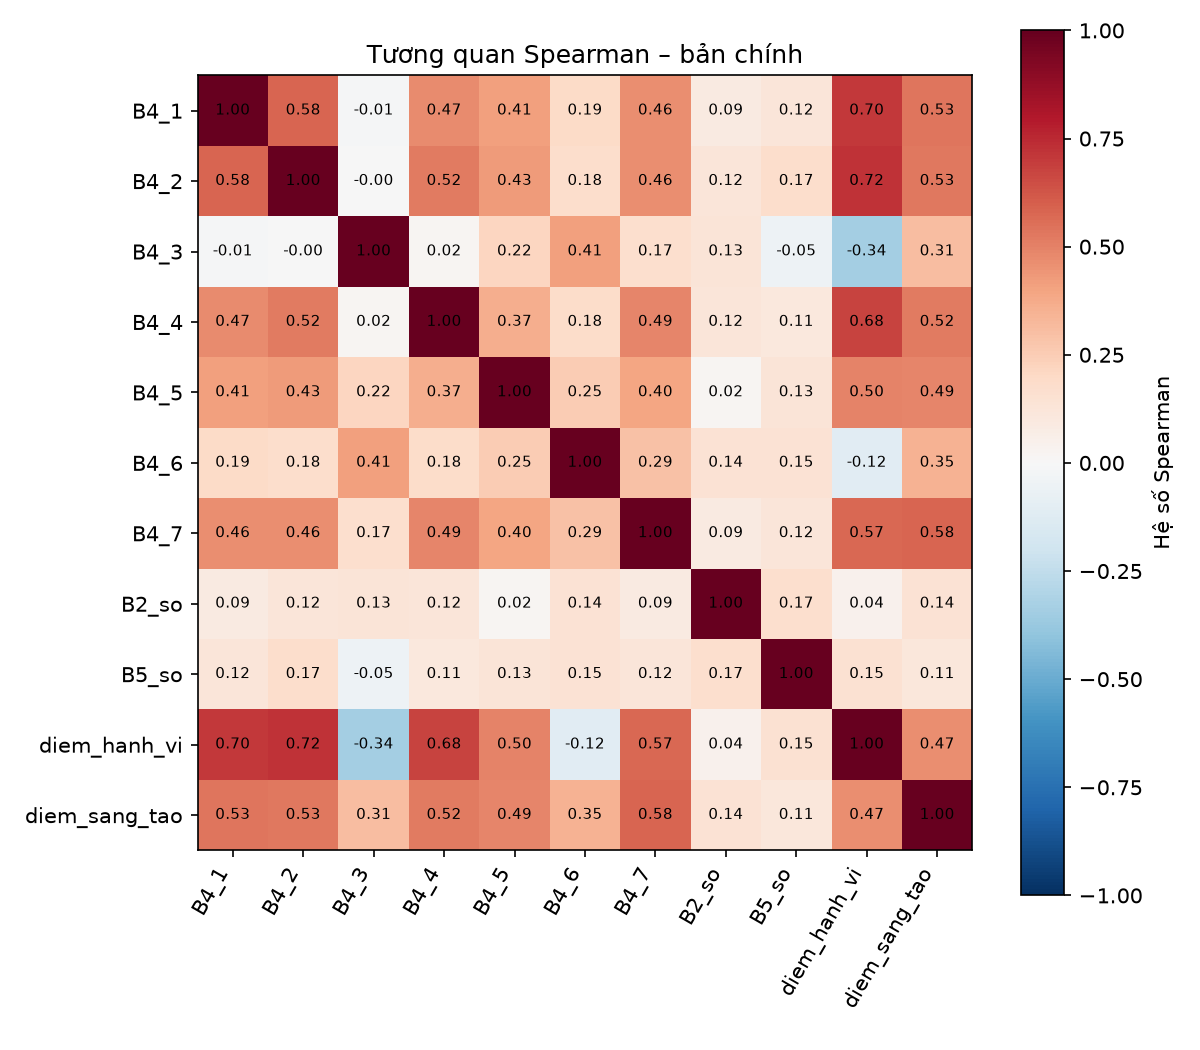

In [7]:
ve_histogram(ban['diem_sang_tao'], 'Phân bố điểm sáng tạo – bản chính', HINH / 'fig_creativity_hist_main.png')
ve_heatmap(ma_tran_rho(t5), 'Tương quan Spearman – bản chính', HINH / 'fig_corr_heatmap_main.png')
from IPython.display import Image
display(Image(HINH / 'fig_creativity_hist_main.png', width=500)); display(Image(HINH / 'fig_corr_heatmap_main.png', width=550))

# 3. Bản chặt (kỳ vọng 297 dòng)

In [8]:
ban = lay_ban(sach, 'chat')   # lấy đúng các dòng thuộc bản chặt
assert len(ban) == 297, len(ban)
print('Bản chặt:', len(ban), 'dòng')

Bản chặt: 297 dòng


### T1 – Mô tả mẫu (bản chặt)
Bảng cho biết **mẫu gồm những ai**: bao nhiêu người ở mỗi cấp học, giới tính, dùng công cụ AI nào, dùng thường xuyên cỡ nào, mỗi lần bao lâu, và thu ở đợt nào. Cột `ty_le_%` là phần trăm trên tổng của bản này. Công cụ AI (B1) cho chọn nhiều nên tổng phần trăm có thể vượt 100.

In [9]:
luu(bang_mo_ta_mau(ban), 'T1_sample_strict.csv')   # T1

,bien,nhom,so_nguoi,ty_le_%
0,Cấp học,THPT,126,42.4
1,Cấp học,Đại học,109,36.7
2,Cấp học,THCS,62,20.9
3,Giới tính,Nữ,175,58.9
4,Giới tính,Nam,115,38.7
5,Giới tính,Khác,7,2.4
6,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",ChatGPT,230,77.4
7,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Gemini,196,66.0
8,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Copilot,45,15.2
9,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Claude,54,18.2


### T3 – Độ tin cậy Cronbach's alpha (bản chặt)
Bảng cho biết **các câu hỏi trong cùng một thang có nhất quán không**: thang sáng tạo tự đánh giá (C1–C5, 5 câu) và thang hành vi dùng AI (B4, 7 câu, đã đảo chiều B4_3 và B4_6 như đã chốt). `co_mau` là số người trả lời đủ mọi câu của thang. Alpha của thang hành vi thường thấp hơn vì 7 câu đo nhiều khía cạnh khác nhau.

In [10]:
luu(bang_alpha(ban), 'T3_alpha_strict.csv')   # T3

,thang_do,so_cau,co_mau,alpha
0,Sáng tạo tự đánh giá (C1–C5),5,297,0.752
1,"Hành vi dùng AI (B4_1..B4_7, đảo B4_3, B4_6)",7,297,0.572


### T4 – So sánh điểm sáng tạo giữa các nhóm (bản chặt)
Bảng cho biết **điểm sáng tạo (0–100) có khác nhau giữa các nhóm không**: theo cấp học, giới tính (A2) và tần suất dùng AI (B2). Hai nhóm dùng Mann-Whitney; từ ba nhóm dùng Kruskal-Wallis (không cần điểm phân phối chuẩn). `hieu_ung` là cỡ hiệu ứng: epsilon bình phương gần 0 là khác biệt rất nhỏ (khoảng 0.01 nhỏ, 0.06 vừa, 0.14 lớn). Nhóm dưới 5 người bị bỏ và ghi ở cột `nhom_bi_bo`. Đây là so sánh mô tả, chưa hiệu chỉnh cho nhiều phép thử.

In [11]:
luu(bang_so_sanh(ban), 'T4_group_compare_strict.csv')   # T4

,bien_nhom,so_nhom,n,phep_thu,thong_ke,p,ten_hieu_ung,hieu_ung,mo_ta_nhom,nhom_bi_bo
0,cap_hoc,3,297,Kruskal-Wallis H,17.997,0.000124,epsilon bình phương,0.054,"THCS: n=62, trung vị=55.0; THPT: n=126, trung ...",
1,A2,3,297,Kruskal-Wallis H,3.468,0.176611,epsilon bình phương,0.005,"Khác: n=7, trung vị=60.0; Nam: n=115, trung vị...",
2,B2,4,297,Kruskal-Wallis H,3.957,0.266103,epsilon bình phương,0.003,"Hầu như mỗi ngày: n=144, trung vị=65.0; Rất hi...",


### T5 – Tương quan Spearman (bản chặt)
Bảng cho biết **hai biến có đi cùng chiều không** (`rho` từ -1 đến 1; gần 0 là gần như không liên quan). Gồm 7 câu B4 (chưa đảo chiều, để xem từng câu), tần suất B2, thời gian B5, điểm hành vi và điểm sáng tạo. `n` là số người có đủ cả hai biến. Tương quan không có nghĩa là nguyên nhân.

In [12]:
t5 = bang_tuong_quan(ban); luu(t5, 'T5_spearman_strict.csv')   # T5

,bien_1,bien_2,rho,p,n
0,B4_1,B4_2,0.534,0.000000,297
1,B4_1,B4_3,-0.075,0.197468,297
2,B4_1,B4_4,0.431,0.000000,297
3,B4_1,B4_5,0.366,0.000000,297
4,B4_1,B4_6,0.151,0.008958,297
5,B4_1,B4_7,0.402,0.000000,297
6,B4_1,B2_so,0.056,0.336759,297
7,B4_1,B5_so,0.101,0.082619,297
8,B4_1,diem_hanh_vi,0.689,0.000000,297
9,B4_1,diem_sang_tao,0.503,0.000000,297


### Hình – bản chặt
Hình 1 là **phân bố điểm sáng tạo** (đường đỏ đứt là ngưỡng 60 và 80 chia mức Thấp / Trung bình / Cao). Hình 2 là **heatmap tương quan** vẽ từ bảng T5 (đỏ là cùng chiều, xanh là ngược chiều).

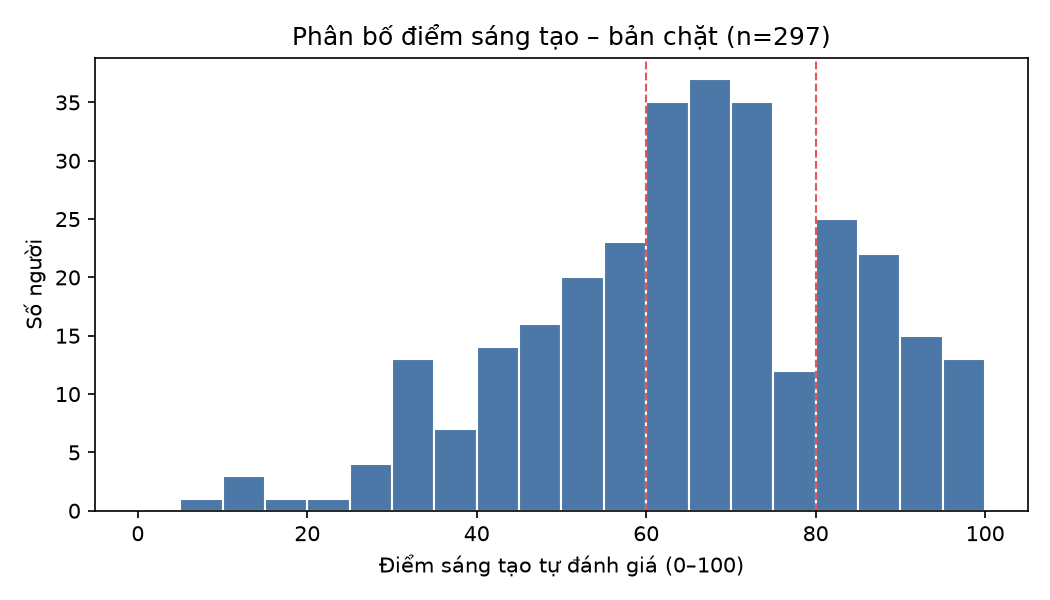

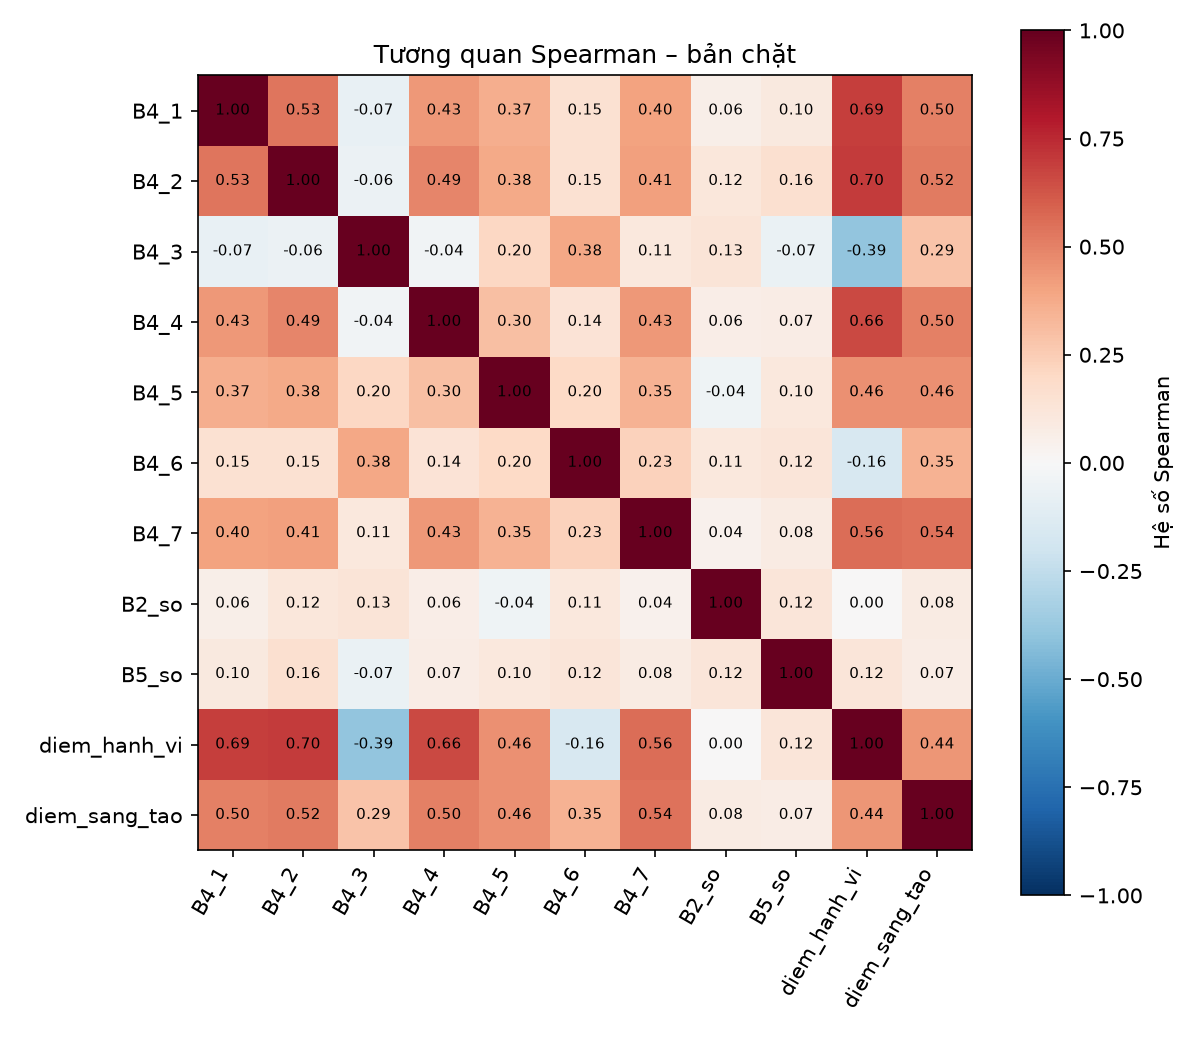

In [13]:
ve_histogram(ban['diem_sang_tao'], 'Phân bố điểm sáng tạo – bản chặt', HINH / 'fig_creativity_hist_strict.png')
ve_heatmap(ma_tran_rho(t5), 'Tương quan Spearman – bản chặt', HINH / 'fig_corr_heatmap_strict.png')
from IPython.display import Image
display(Image(HINH / 'fig_creativity_hist_strict.png', width=500)); display(Image(HINH / 'fig_corr_heatmap_strict.png', width=550))

# 4. Bản rất chặt (kỳ vọng 231 dòng)

In [14]:
ban = lay_ban(sach, 'rat_chat')   # lấy đúng các dòng thuộc bản rất chặt
assert len(ban) == 231, len(ban)
print('Bản rất chặt:', len(ban), 'dòng')

Bản rất chặt: 231 dòng


### T1 – Mô tả mẫu (bản rất chặt)
Bảng cho biết **mẫu gồm những ai**: bao nhiêu người ở mỗi cấp học, giới tính, dùng công cụ AI nào, dùng thường xuyên cỡ nào, mỗi lần bao lâu, và thu ở đợt nào. Cột `ty_le_%` là phần trăm trên tổng của bản này. Công cụ AI (B1) cho chọn nhiều nên tổng phần trăm có thể vượt 100.

In [15]:
luu(bang_mo_ta_mau(ban), 'T1_sample_very_strict.csv')   # T1

,bien,nhom,so_nguoi,ty_le_%
0,Cấp học,THPT,105,45.5
1,Cấp học,Đại học,74,32.0
2,Cấp học,THCS,52,22.5
3,Giới tính,Nữ,132,57.1
4,Giới tính,Nam,92,39.8
5,Giới tính,Khác,7,3.0
6,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",ChatGPT,173,74.9
7,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Gemini,146,63.2
8,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Copilot,36,15.6
9,"Công cụ AI (B1, chọn nhiều nên tổng > 100%)",Claude,41,17.7


### T3 – Độ tin cậy Cronbach's alpha (bản rất chặt)
Bảng cho biết **các câu hỏi trong cùng một thang có nhất quán không**: thang sáng tạo tự đánh giá (C1–C5, 5 câu) và thang hành vi dùng AI (B4, 7 câu, đã đảo chiều B4_3 và B4_6 như đã chốt). `co_mau` là số người trả lời đủ mọi câu của thang. Alpha của thang hành vi thường thấp hơn vì 7 câu đo nhiều khía cạnh khác nhau.

In [16]:
luu(bang_alpha(ban), 'T3_alpha_very_strict.csv')   # T3

,thang_do,so_cau,co_mau,alpha
0,Sáng tạo tự đánh giá (C1–C5),5,231,0.729
1,"Hành vi dùng AI (B4_1..B4_7, đảo B4_3, B4_6)",7,231,0.682


### T4 – So sánh điểm sáng tạo giữa các nhóm (bản rất chặt)
Bảng cho biết **điểm sáng tạo (0–100) có khác nhau giữa các nhóm không**: theo cấp học, giới tính (A2) và tần suất dùng AI (B2). Hai nhóm dùng Mann-Whitney; từ ba nhóm dùng Kruskal-Wallis (không cần điểm phân phối chuẩn). `hieu_ung` là cỡ hiệu ứng: epsilon bình phương gần 0 là khác biệt rất nhỏ (khoảng 0.01 nhỏ, 0.06 vừa, 0.14 lớn). Nhóm dưới 5 người bị bỏ và ghi ở cột `nhom_bi_bo`. Đây là so sánh mô tả, chưa hiệu chỉnh cho nhiều phép thử.

In [17]:
luu(bang_so_sanh(ban), 'T4_group_compare_very_strict.csv')   # T4

,bien_nhom,so_nhom,n,phep_thu,thong_ke,p,ten_hieu_ung,hieu_ung,mo_ta_nhom,nhom_bi_bo
0,cap_hoc,3,231,Kruskal-Wallis H,7.219,0.027063,epsilon bình phương,0.023,"THCS: n=52, trung vị=50.0; THPT: n=105, trung ...",
1,A2,3,231,Kruskal-Wallis H,1.053,0.590786,epsilon bình phương,0.000,"Khác: n=7, trung vị=60.0; Nam: n=92, trung vị=...",
2,B2,3,228,Kruskal-Wallis H,4.620,0.099244,epsilon bình phương,0.012,"Hầu như mỗi ngày: n=105, trung vị=60.0; Vài lầ...",Rất hiếm khi


### T5 – Tương quan Spearman (bản rất chặt)
Bảng cho biết **hai biến có đi cùng chiều không** (`rho` từ -1 đến 1; gần 0 là gần như không liên quan). Gồm 7 câu B4 (chưa đảo chiều, để xem từng câu), tần suất B2, thời gian B5, điểm hành vi và điểm sáng tạo. `n` là số người có đủ cả hai biến. Tương quan không có nghĩa là nguyên nhân.

In [18]:
t5 = bang_tuong_quan(ban); luu(t5, 'T5_spearman_very_strict.csv')   # T5

,bien_1,bien_2,rho,p,n
0,B4_1,B4_2,0.602,0.000000,231
1,B4_1,B4_3,-0.267,0.000041,231
2,B4_1,B4_4,0.470,0.000000,231
3,B4_1,B4_5,0.343,0.000000,231
4,B4_1,B4_6,0.102,0.122400,231
5,B4_1,B4_7,0.435,0.000000,231
6,B4_1,B2_so,0.061,0.352962,231
7,B4_1,B5_so,0.097,0.141398,231
8,B4_1,diem_hanh_vi,0.733,0.000000,231
9,B4_1,diem_sang_tao,0.511,0.000000,231


### Hình – bản rất chặt
Hình 1 là **phân bố điểm sáng tạo** (đường đỏ đứt là ngưỡng 60 và 80 chia mức Thấp / Trung bình / Cao). Hình 2 là **heatmap tương quan** vẽ từ bảng T5 (đỏ là cùng chiều, xanh là ngược chiều).

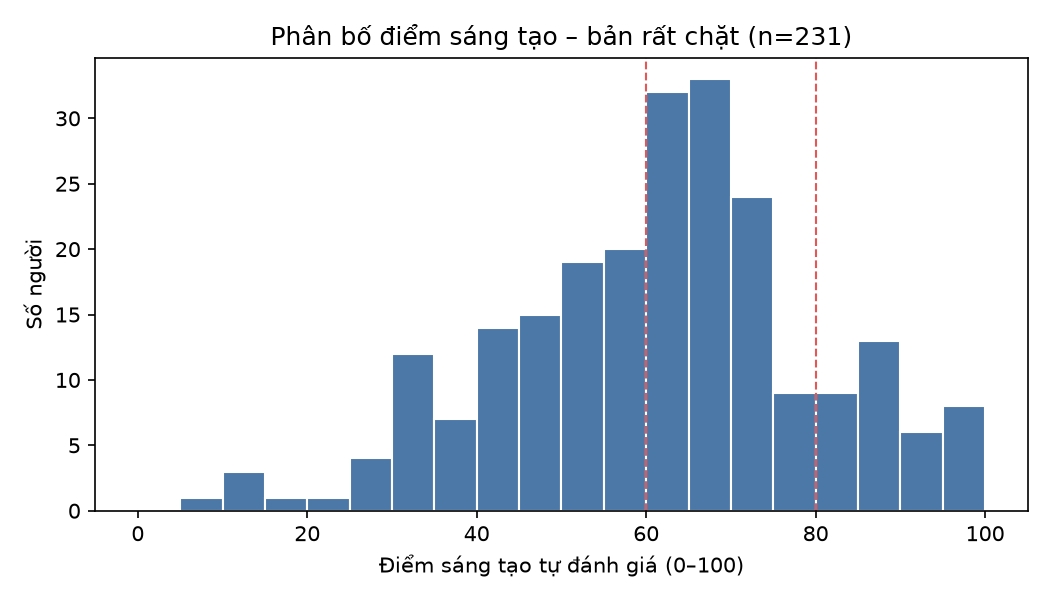

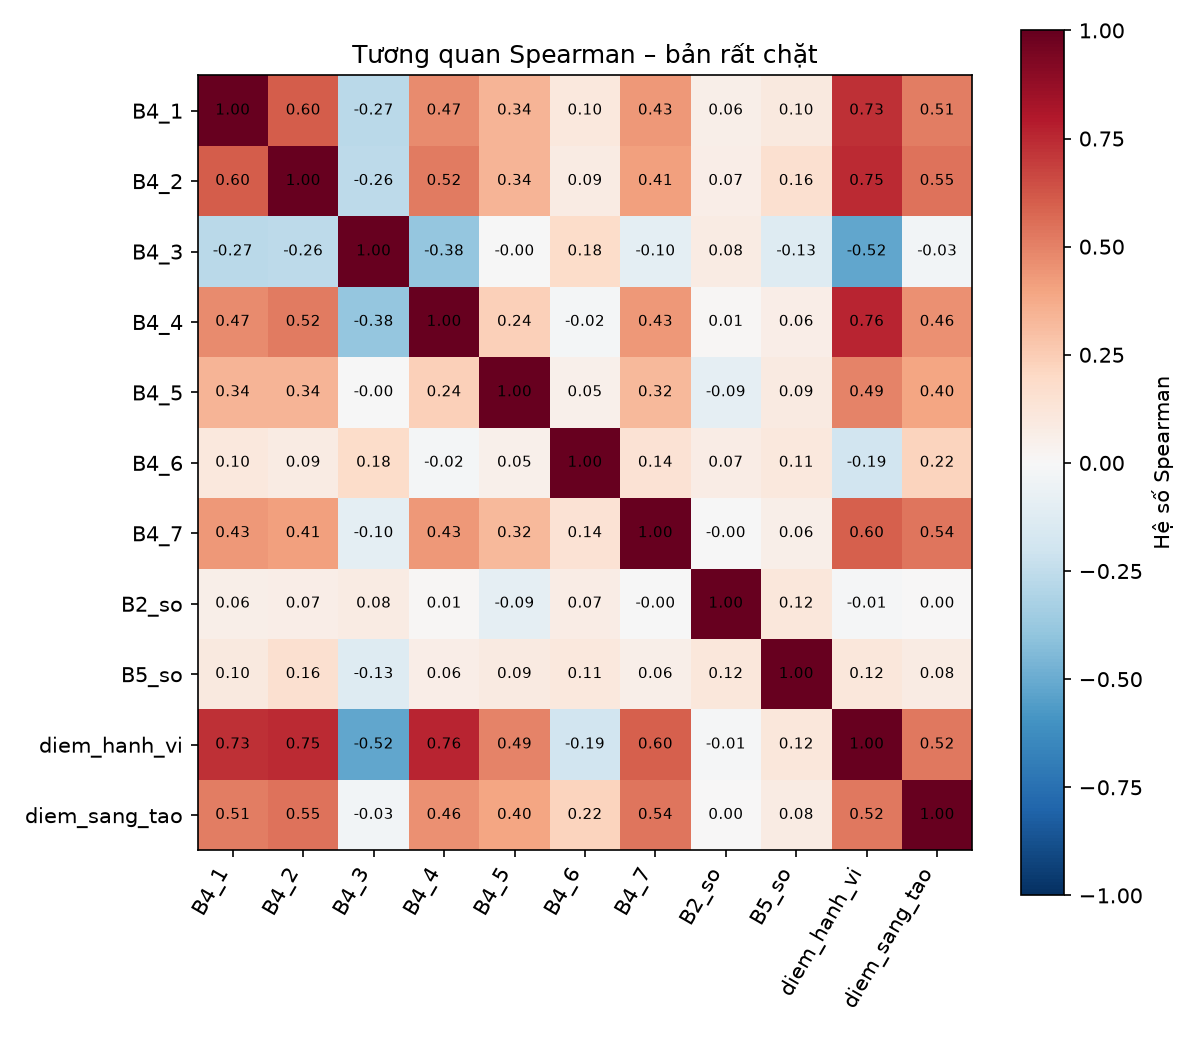

In [19]:
ve_histogram(ban['diem_sang_tao'], 'Phân bố điểm sáng tạo – bản rất chặt', HINH / 'fig_creativity_hist_very_strict.png')
ve_heatmap(ma_tran_rho(t5), 'Tương quan Spearman – bản rất chặt', HINH / 'fig_corr_heatmap_very_strict.png')
from IPython.display import Image
display(Image(HINH / 'fig_creativity_hist_very_strict.png', width=500)); display(Image(HINH / 'fig_corr_heatmap_very_strict.png', width=550))

# 5. Kiểm tra cuối
Đếm file đã lưu: kỳ vọng 12 bảng CSV (T1, T3, T4, T5 × 3 bản) và 6 hình PNG.

In [20]:
print('Bảng CSV:', len(list(BANG.glob('T[1345]_*.csv'))), '| Hình PNG:', len(list(HINH.glob('fig_*.png'))))

Bảng CSV: 12 | Hình PNG: 6
